# 10 — SM×SM heatmap of remote shared-memory (DSMEM) latency on the H100

**Goal.** Measure, on one H100 NVL at a locked 1635 MHz SM clock, the latency of a remote shared-memory access for **every pair of SMs that can share a thread-block cluster** (1876 ordered pairs), and find out whether the SM-to-SM network inside a GPC has any internal structure, for example:
- a shortcut between the two SMs of a TPC;
- a step between groups of TPCs (the CPC level, three TPCs per group);
- direction asymmetry;
- differences between the 12-, 16- and 18-SM GPCs.

Three quantities are measured per pair:
- the dependent-load latency of a single thread (zero load);
- the latency per request when one SM streams the other's memory (loaded);
- the round trip of a store-to-flag hand-off (visibility).

All three are also measured under light and heavy background load.

Why it matters: in a 3D-stacked design the SMs of a GPC could be placed on different dies or at different distances from the network. If the network is flat, only its base latency matters. If it is hierarchical, the cost depends on which SMs talk and placement becomes a design parameter.

## 2. Background

**Clusters and DSMEM.** A Hopper kernel can be launched with a *cluster* dimension. Up to 16 CTAs of a cluster run at the same time on SMs of one GPC (graphics processing cluster), and each can read and write the shared memory of the others through the `.shared::cluster` address space. A remote load leaves the issuing SM, crosses the GPC's SM-to-SM network to the SM that owns the address, is served there, and the reply returns. `mapa.shared::cluster` turns a local shared-memory offset into the address of the same offset in CTA `rank`, and `ld.shared::cluster` reads it.

```
mapa.shared::cluster.u32  base, region, dst;     // address of `region` in CTA `dst`
ld.shared::cluster.u32    v, [base + v];         // dependent chain: the value is the next offset
```

**GPC, TPC, CPC.** This H100 has 8 GPCs with 12, 16, 16, 16, 18, 18, 18 and 18 SMs. Two SMs form a TPC (SMs 2t and 2t+1). Within a GPC we number the TPCs 0, 1, 2, … in ascending SM id (the *TPC index*). Hopper GPCs are described as built from CPCs of three TPCs each. If that level existed in the network, pairs inside one group would be faster than pairs across groups. The grouping that is usually assumed is CPC = TPC index mod 3, for example {0, 3, 6}, {1, 4, 7}, {2, 5} in a GPC of 8 TPCs. Eight SMs (TPCs 62–65: SMs 124–131) only ever join clusters of 2 CTAs, together with their TPC mate; the 12-SM GPC therefore hosts clusters of at most 8 CTAs.

**What a structure would look like.** If every request and reply passes one central point of the GPC, a pair's latency is a sum of two per-SM terms, the delay from the source SM to the centre and from the centre to the destination SM:
$$L(i,j) = p(i) + p(j)\quad\text{(or, more generally, } L(i,j) = \mu + a(i) + b(j)\text{)}.$$
A hierarchical network (shortcuts inside a TPC or CPC, or a ring or mesh) adds a term that depends on the *pair*, which shows up as a structured residual of this additive fit.

**Three ways to measure a pair.**
- **Chase:** one thread issues dependent loads, so one request is in flight at a time and the time per load is the pure round trip.
- **Loaded:** 1024 threads each keep 8 independent loads in flight, and the time from the issue of a group of loads to its last reply is measured.
- **Visibility ping-pong:** one SM stores a value into the other's shared memory and the other waits for it and answers. Here the hand-off is signalled either through an mbarrier (`st.async`) or through a plain store that the receiver polls.

## 3. Experimental setup

In [1]:
%matplotlib inline
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, "src")
from common10 import (MANDATORY, RES, coschedulable_pairs, fit_additive, full_runs, mad, pair_table, read_runs, relation3, runs,
                      sm_map)

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # fixed categorical order
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.prop_cycle": plt.cycler(color=C),
                     "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6})
pd.set_option("display.width", 200)
pd.set_option("display.precision", 2)

RUNS = full_runs()
SCH = ["E", "A", "C", "B", "D", "D8"]
IDS = [RUNS[s] for s in SCH]
IDLE = ["A", "B", "C", "D", "D8"]
M = sm_map()
TPCI = M.tpc_index.to_dict()
GPC = M.gpc.to_dict()

P = read_runs("10__heatmap__pairs.csv", IDS)
LO = read_runs("10__heatmap__loaded.csv", IDS)
VT = read_runs("10__heatmap__visibility_trials.csv", IDS)
SE = read_runs("10__heatmap__sessions.csv", IDS + [RUNS["steer"]])
MHZ = float(P.sm_clock_mhz.median())
REM = P[P.smid_src != P.smid_dst].copy()
IDL = REM[REM.schedule.isin(IDLE) & (REM.load_condition == "idle")]


def latest(f):
    d = pd.read_csv(f"{RES}/{f}")
    return d[d.run_id == d.run_id.max()]


MODEL = latest("10__heatmap__model.csv")


def ns_axis(ax, which="y"):
    f = (lambda c: c / MHZ * 1e3, lambda n: n * MHZ / 1e3)
    sec = ax.secondary_yaxis("right", functions=f) if which == "y" else ax.secondary_xaxis("top", functions=f)
    (sec.set_ylabel if which == "y" else sec.set_xlabel)("ns at the measured SM clock")
    return sec


def order_gpc(g):
    # SMs of GPC g ordered by TPC index, then smid
    s = M[M.gpc == g]
    return list(s.sort_values(["tpc_index"]).index)

In [2]:
# Device and fixed configuration, from the mandatory CSV columns of the runs analysed here
r0 = P.iloc[0]
ncu = latest("10__heatmap__ncu_k1.csv")
display(pd.DataFrame({"": [r0.gpu_name, r0.sm_count, f"{MHZ:.0f} MHz (NVML after every launch, median; locked at 1635 MHz)",
                           f"{ncu['sm__cycles_elapsed.avg.per_second'].astype(float).median() / 1e6:.0f} MHz (ncu, profiled single-cluster K1 launches; most SMs idle, the per-SM rollup of short kernels is approximate)",
                           f"{r0.mem_clock_mhz} MHz", "400 W", "enabled / disabled", r0.cuda_version, r0.driver_version,
                           "-arch=sm_90a -O3 -lineinfo"]},
                     index=["GPU", "SMs", "SM clock", "SM clock under ncu", "memory clock", "power limit", "ECC / MIG", "CUDA",
                            "driver", "nvcc"]))
dpath = f"{RES}/10__heatmap__discards.csv"
disc = pd.read_csv(dpath) if os.path.getsize(dpath) else pd.DataFrame(columns=["run_id"])
inv = []
for s in SCH + ["steer"]:
    se = SE[SE.run_id == RUNS[s]]
    inv.append([s, RUNS[s], len(se), int((se.outcome == "ok").sum()), int((se.outcome == "unplaceable").sum()),
                int(se.n_launches.sum()), int((disc.run_id == RUNS[s]).sum())])
display(pd.DataFrame(inv, columns=["schedule", "run_id", "sessions", "ok", "unplaceable", "recorded launches", "discarded launches"])
        .set_index("schedule"))

,
GPU,NVIDIA H100 NVL
SMs,132
SM clock,"1635 MHz (NVML after every launch, median; loc..."
SM clock under ncu,"1676 MHz (ncu, profiled single-cluster K1 laun..."
memory clock,2619 MHz
power limit,400 W
ECC / MIG,enabled / disabled
CUDA,12.9
driver,580.126.20
nvcc,-arch=sm_90a -O3 -lineinfo


,run_id,sessions,ok,unplaceable,recorded launches,discarded launches
schedule,,,,,,
E,2026-10-26T04:20:28.828+00:00,40,40,0,40,0
A,2026-10-26T04:20:33.745+00:00,290,290,0,1740,0
C,2026-10-26T04:24:19.824+00:00,80,80,0,480,0
B,2026-10-26T04:24:24.517+00:00,992,992,0,2144,0
D,2026-10-26T04:25:33.072+00:00,210,210,0,1260,0
D8,2026-10-26T04:28:14.950+00:00,120,120,0,720,0
steer,2026-10-26T04:20:27.915+00:00,72,72,0,72,0


**What is measured and how.**

- **One active cluster per launch, steered by placeholder CTAs.** A lone cluster always lands on the same SMs: CS 16 in one particular GPC, CS 8 in the 12-SM GPC. Full waves of clusters leave the same two SMs out of each 18-SM GPC. To place the cluster on a chosen set *T* of SMs, a placeholder kernel is started first: 66 clusters of 2 CTAs with 1024 threads and 200 KB of shared memory each, so exactly one CTA per SM on all 132 SMs, and the two CTAs of a pair are TPC mates. Each pair reads its two `%smid` values; it exits if either SM belongs to *T* and stays resident otherwise. When all 66 pairs have decided, the measuring cluster (|*T*| CTAs, 200 KB each) is launched on a second stream. The only free SMs are those of *T*, so it must run there. Afterwards the host releases the placeholders through a flag in host-mapped memory.
  - Every measuring CTA records `%smid`, `%clusterid`, `%cluster_ctarank`.
  - A launch whose ranks were not on distinct SMs of *T*, or whose NVML sample after the launch showed a throttle reason or a clock below the lock, would be discarded and repeated (counts above: none).
  - A cluster that had not started 1 s after its launch would have made the session "unplaceable" (none).
  - Every 4-TPC subset of every GPC accepted an 8-CTA cluster, and every 8-TPC subset of the 18-SM GPCs accepted a 16-CTA cluster.
- **Load conditions** = what the placeholders do while resident:
  - *idle*: one thread sleeps and polls the release flag every 20 µs;
  - *light*: all 1024 threads stream the CTA's own 192 KiB of shared memory with `ld.shared`, 8 loads in flight per thread;
  - *heavy*: the same, but reading the TPC mate's shared memory with `ld.shared::cluster`, i.e. SM-to-SM traffic at the per-SM injection limit.

  Inside the target GPC, placeholders sit only on SMs the cluster does not use: the left-out TPC of an 18-SM GPC, the mate-only TPC of G4/G5, or the other half of the GPC for CS 8. *none* = no placeholders at all, the hardware's own placement of a lone cluster (a control).
- **Chase (K1).** Each CTA writes a stride-1 chain of 1024 four-byte offsets into its own shared memory. Source ranks take turns, separated by `cluster.sync()`, so one SM of the cluster is active at a time. The source's lane 0 chases every destination's chain, its own included: 64 untimed hops, then 4096 timed dependent hops (`v = ld.shared::cluster [base + v]`). The time per hop is (t1 − t0)/4096 of `%clock64`; the fixed timer and loop cost (≤ 0.05 cycles per hop) is not subtracted. The final offset is checked on the host. Then 256 further hops are timed one by one (*fine pass*; each value includes the timer pair, ≈ 3 cycles).
- **Loaded (K1f).** 1024 threads of the source each issue 6 groups of 8 independent 4-B `ld.shared::cluster` (each warp load = one contiguous 128 B) into the destination's 192 KiB. A sample is the `%clock64` time from the issue of a group until the sum of its 8 values is available: 6144 samples per pair.
- **Visibility (K2).** For every ordered pair (q, p) in turn, lane 0 of q and lane 0 of p ping-pong 1000 times, and q measures the round trip with `%clock64`. Two methods:
  - `st_async_mbarrier`: `st.async` of the value with `complete_tx` on the peer's mbarrier, waited for with `mbarrier.try_wait.parity`;
  - `st_plain`: `st.shared::cluster` of the value, polled by the peer with `ld.volatile.shared`.

  The `_nogt` variants contain no global-timer read in the loop (clean round trip). The other variants also record `%globaltimer` at both ends (one-way ns in 32-ns ticks).
- **SASS.** The timed chase loop is 16 × (`IMAD.IADD` + 2 `MOV` + `LD.E`) per iteration, each load depending on the previous one. The idle placeholder loop is one `LDG.E.STRONG.GPU` of the flag + `NANOSLEEP`. The heavy loop is 8 `LD.E` (DSMEM) per thread and group.

In [3]:
sched = pd.DataFrame([
    ["E", "none", "16 / 8", "lone cluster without placeholders (hardware placement)", "20 + 20", "chase"],
    ["A", "idle", "16", "G1–G5: the 16 cluster-capable SMs × 40; G6/G7: 9 sets, one TPC left out × 5", "290", "chase, loaded, visibility"],
    ["C", "idle", "2", "TPCs 62–65 (SMs 124–131, pair only with their mate) × 20", "80", "chase, loaded, visibility"],
    ["B", "idle", "8", "G0's 8 capable SMs × 40 (+ visibility); every 4-TPC subset: G1–G5 70 × 2, G6/G7 126 × 1", "992", "chase, loaded"],
    ["D", "idle / light / heavy", "16", "G1–G7 × 10 per condition, interleaved", "210", "chase, loaded, visibility"],
    ["D8", "idle / light / heavy", "8", "G1 and G6: TPC-index subsets {0–3}, {4–7}, even, odd × 5 per condition", "120", "chase, loaded, visibility"],
], columns=["schedule", "load condition", "CS", "target sets", "sessions", "kernels"]).set_index("schedule")
display(sched)
cov_pairs = coschedulable_pairs(M)
ch_tab = pair_table(IDL, "cycles_per_hop")
meas = set(zip(ch_tab.smid_src, ch_tab.smid_dst))
display(pd.DataFrame({"": [len(cov_pairs), len(meas & set(cov_pairs)), len(meas - set(cov_pairs)), int(ch_tab.n.min()), int(ch_tab.n.median()),
                           int(ch_tab.n.max())]},
                     index=["co-schedulable ordered SM pairs", "measured (idle)", "measured but not co-schedulable", "launches per pair: min",
                            "launches per pair: median", "launches per pair: max"]))

,load condition,CS,target sets,sessions,kernels
schedule,,,,,
E,none,16 / 8,lone cluster without placeholders (hardware pl...,20 + 20,chase
A,idle,16,G1–G5: the 16 cluster-capable SMs × 40; G6/G7:...,290,"chase, loaded, visibility"
C,idle,2,"TPCs 62–65 (SMs 124–131, pair only with their ...",80,"chase, loaded, visibility"
B,idle,8,G0's 8 capable SMs × 40 (+ visibility); every ...,992,"chase, loaded"
D,idle / light / heavy,16,"G1–G7 × 10 per condition, interleaved",210,"chase, loaded, visibility"
D8,idle / light / heavy,8,"G1 and G6: TPC-index subsets {0–3}, {4–7}, eve...",120,"chase, loaded, visibility"


,
co-schedulable ordered SM pairs,1876
measured (idle),1876
measured but not co-schedulable,0
launches per pair: min,20
launches per pair: median,80
launches per pair: max,130


2 unrecorded warm-up sessions precede every schedule. **Raw data and reductions.** Every per-launch, per-pair value of the chase (4096-hop mean and the median, MAD, mean, min and max of its 256 fine-pass hops), of the loaded run (mean and percentiles of the 6144 samples) and of the ping-pong (median, MAD, mean, p5, p95, min and max of the 1000 trials) is kept. Because the individual samples would amount to billions of values, they are stored as exact reductions:
- per pair and condition, the histogram of every fine-pass hop, of every loaded sample and of every round trip;
- per pair and hop index, the sum, sum of squares, min and max of the fine-pass hops over all launches;
- the complete per-hop series of the first two launches of every GPC and cluster size.

What is not kept is the order of individual samples within a launch (outside those series).

## 4. Results

### 4.1 The full matrix (Fig. 2 and Fig. 1)

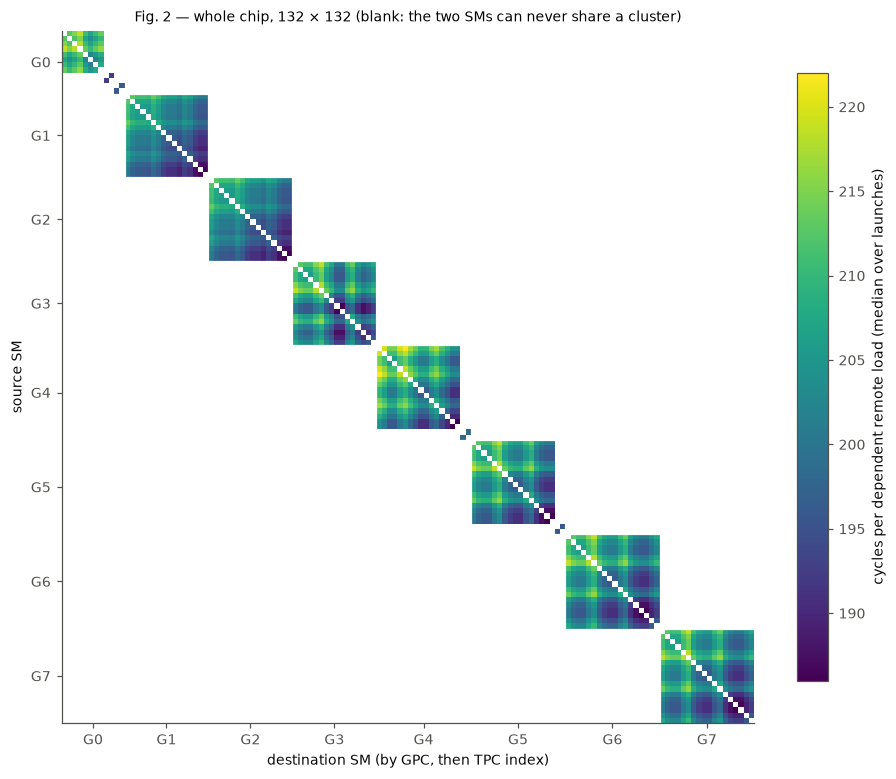

In [4]:
mat = ch_tab.pivot(index="smid_src", columns="smid_dst", values="median")
order = [s for g in range(8) for s in order_gpc(g)]
full = mat.reindex(index=order, columns=order)
vmin, vmax = np.nanmin(full.values), np.nanmax(full.values)
fig, ax = plt.subplots(figsize=(8.6, 7.4))
im = ax.imshow(full.values, cmap="viridis", vmin=vmin, vmax=vmax, interpolation="nearest")
edges = np.cumsum([len(order_gpc(g)) for g in range(8)])
for e in edges[:-1]:
    ax.axhline(e - 0.5, color="w", lw=0.8); ax.axvline(e - 0.5, color="w", lw=0.8)
mids = edges - np.array([len(order_gpc(g)) for g in range(8)]) / 2
ax.set_xticks(mids - 0.5); ax.set_xticklabels([f"G{g}" for g in range(8)]); ax.set_yticks(mids - 0.5); ax.set_yticklabels([f"G{g}" for g in range(8)])
ax.grid(False); ax.set_xlabel("destination SM (by GPC, then TPC index)"); ax.set_ylabel("source SM")
plt.colorbar(im, ax=ax, shrink=0.8, label="cycles per dependent remote load (median over launches)")
ax.set_title("Fig. 2 — whole chip, 132 × 132 (blank: the two SMs can never share a cluster)", fontsize=9)
plt.tight_layout(); plt.show()

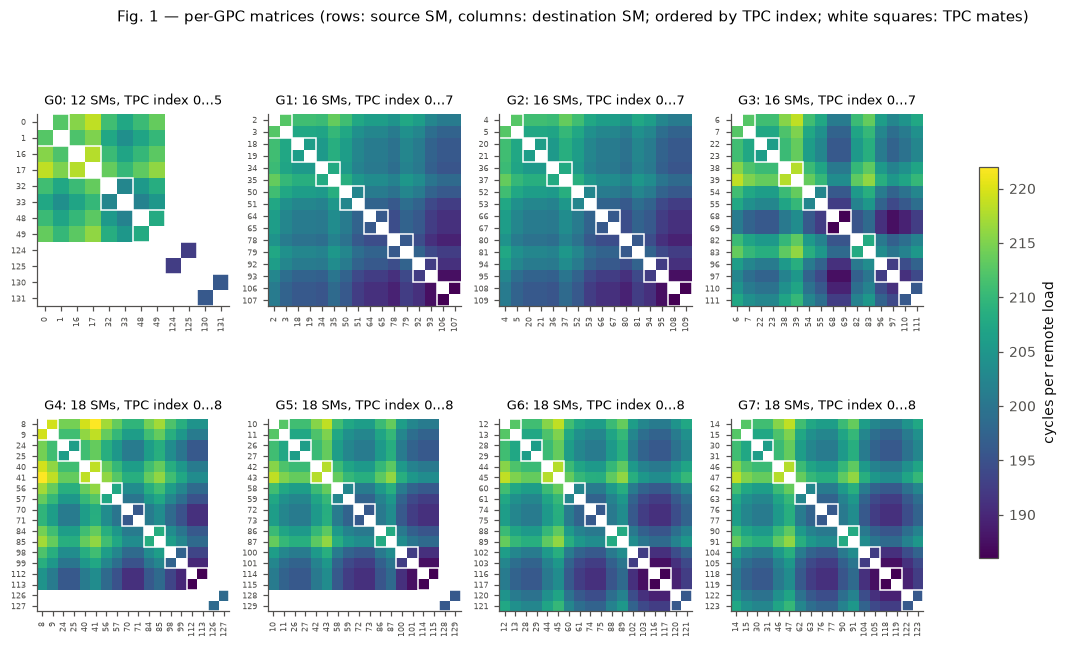

,SMs,count,min,5%,50%,95%,max
gpc,,,,,,,
0,12,60.0,192.5,196.0,210.0,218.0,218.5
1,16,240.0,186.0,191.0,200.5,210.0,213.5
2,16,240.0,186.0,191.0,200.5,210.0,213.5
3,16,240.0,186.0,191.0,202.5,213.5,218.5
4,18,242.0,186.0,191.0,205.0,217.0,222.0
5,18,242.0,186.0,191.0,202.5,213.5,218.5
6,18,306.0,186.0,191.0,202.0,213.5,218.5
7,18,306.0,186.0,191.0,202.0,213.5,218.5


,count,mean,std,min,50%,95%,99%,max
per-pair MAD over launches (cycles),1876.0000,0.0001,0.0001,0.0000,0.0000,0.0003,0.0004,0.0005


In [5]:
fig, axs = plt.subplots(2, 4, figsize=(13, 6.6))
for g, ax in zip(range(8), axs.flat):
    o = order_gpc(g)
    sub = mat.reindex(index=o, columns=o)
    im = ax.imshow(sub.values, cmap="viridis", vmin=vmin, vmax=vmax, interpolation="nearest")
    for k in range(0, len(o), 2):  # TPC boundaries
        ax.add_patch(plt.Rectangle((k - 0.5, k - 0.5), 2, 2, fill=False, ec="w", lw=1.0))
    ax.set_xticks(range(len(o))); ax.set_xticklabels(o, rotation=90, fontsize=5.5)
    ax.set_yticks(range(len(o))); ax.set_yticklabels(o, fontsize=5.5)
    ax.grid(False)
    ax.set_title(f"G{g}: {len(o)} SMs, TPC index 0…{len(o) // 2 - 1}", fontsize=8.5)
fig.colorbar(im, ax=axs, shrink=0.7, label="cycles per remote load")
fig.suptitle("Fig. 1 — per-GPC matrices (rows: source SM, columns: destination SM; ordered by TPC index; white squares: TPC mates)", fontsize=9.5)
plt.show()
t = ch_tab.assign(gpc=ch_tab.smid_src.map(GPC)).groupby("gpc")["median"].describe(percentiles=[0.05, 0.5, 0.95])
t.insert(0, "SMs", M.groupby("gpc").size())
display(t[["SMs", "count", "min", "5%", "50%", "95%", "max"]].style.format(precision=1)
        .set_caption("Remote pairs per GPC: cycles per load (pair medians)"))
display(pd.DataFrame({"per-pair MAD over launches (cycles)": ch_tab["mad"].describe(percentiles=[0.5, 0.95, 0.99])}).T.style.format(precision=4))

**Reading Fig. 1 and 2.**
- Every one of the 1876 co-schedulable ordered pairs was measured, each in 20–150 launches. A pair's value is the same in every launch: the median absolute deviation over launches is 0 for most pairs and at most 0.0005 cycles.
- The values are whole cycles plus 0.005, the fixed timer and loop cost (20 cycles) spread over 4096 hops. The pair latency is therefore a fixed, integer number of cycles.
- Remote loads cost **186–222 cycles** (median 202). Within a GPC the matrix has a clear pattern of rows and columns but no blocks: neither the TPC squares on the diagonal nor groups of TPCs stand out. Each row looks like every other row shifted by a constant, and so does each column.
- The 12-SM GPC is the slowest (median 210). The 16- and 18-SM GPCs lie between 200 and 205.

### 4.2 An exactly additive matrix: one delay per SM

In [6]:
cap = ch_tab.smid_src.map(M.capable) & ch_tab.smid_dst.map(M.capable)
d = ch_tab[cap].copy()
# symmetric model without intercept: L(i, j) = p(i) + p(j); identifiable because each GPC's pair graph has triangles
sms = np.unique(d[["smid_src", "smid_dst"]].values)
ix = {s: k for k, s in enumerate(sms)}
X = np.zeros((len(d), len(sms)))
for r, (a, b) in enumerate(d[["smid_src", "smid_dst"]].values):
    X[r, ix[a]] += 1; X[r, ix[b]] += 1
pv, *_ = np.linalg.lstsq(X, d["median"].values, rcond=None)
d["fit"] = X @ pv
d["resid"] = d["median"] - d["fit"]
PORT = pd.Series(pv, index=sms, name="p")
fa = fit_additive(d[["smid_src", "smid_dst"]].values, d["median"].values)
asym = (pd.Series(fa["a"]) - pd.Series(fa["b"]))
rows = []
for g in range(8):
    dg = d[d.smid_src.map(GPC) == g]
    rows.append([f"G{g}", len(dg), dg["median"].std(), dg.resid.std(), dg.resid.abs().max(),
                 (asym[[s for s in asym.index if GPC[s] == g]] - asym[[s for s in asym.index if GPC[s] == g]].mean()).abs().max()])
rows.append(["all", len(d), d["median"].std(), d.resid.std(), d.resid.abs().max(), (asym - asym.mean()).abs().max()])
display(pd.DataFrame(rows, columns=["GPC", "pairs", "std of pair latencies", "residual std, L = p(i) + p(j)", "max |residual|",
                                    "max |a(i) − b(i)| (source vs destination term)"]).set_index("GPC").style.format("{:.4f}", subset=pd.IndexSlice[:, ["std of pair latencies", "residual std, L = p(i) + p(j)", "max |residual|", "max |a(i) − b(i)| (source vs destination term)"]])
        .set_caption("Additive fits of the chase matrix (cluster-capable pairs; mate-only TPCs separately below)"))
sym = d.merge(d, left_on=["smid_src", "smid_dst"], right_on=["smid_dst", "smid_src"], suffixes=("", "_rev"))
display(Markdown(f"Direction: |L(i, j) − L(j, i)| over {len(sym) // 2} unordered pairs: median {(sym['median'] - sym['median_rev']).abs().median():.4f}, "
                 f"max {(sym['median'] - sym['median_rev']).abs().max():.4f} cycles."))

,pairs,std of pair latencies,"residual std, L = p(i) + p(j)",max |residual|,max |a(i) − b(i)| (source vs destination term)
GPC,,,,,
G0,56,4.3412,0.0001,0.0002,0.0001
G1,240,5.9357,0.0000,0.0002,0.0000
G2,240,5.9357,0.0000,0.0001,0.0000
G3,240,7.1006,0.0000,0.0001,0.0000
G4,240,7.4968,0.0001,0.0003,0.0001
G5,240,7.0633,0.0001,0.0003,0.0000
G6,306,6.8730,0.0002,0.0004,0.0001
G7,306,6.8730,0.0001,0.0004,0.0001
all,1868,7.0248,0.0001,0.0004,0.0001


Direction: |L(i, j) − L(j, i)| over 934 unordered pairs: median 0.0000, max 0.0005 cycles.

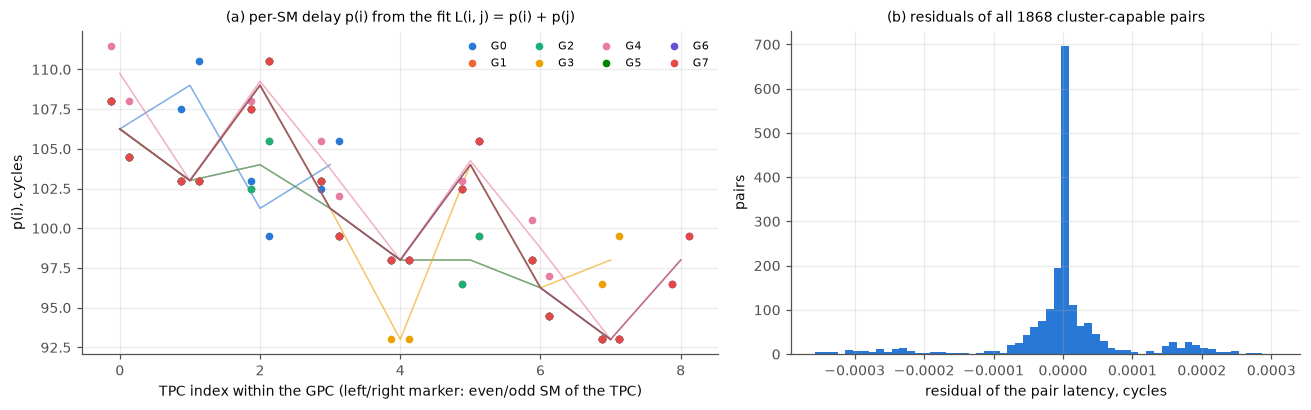

tpc_index,0,1,2,3,4,5,6,7,8
gpc,,,,,,,,,
0,106.3,109.0,101.3,104.0,,,,,
1,106.3,103.0,104.0,101.3,98.0,98.0,96.3,93.0,
2,106.3,103.0,104.0,101.3,98.0,98.0,96.3,93.0,
3,106.3,103.0,109.0,101.3,93.0,104.0,96.3,98.0,
4,109.8,103.0,109.3,103.8,98.0,104.3,98.8,93.0,
5,106.3,103.0,109.0,101.3,98.0,104.0,96.3,93.0,
6,106.3,103.0,109.0,101.3,98.0,104.0,96.3,93.0,98.0
7,106.3,103.0,109.0,101.3,98.0,104.0,96.3,93.0,98.0


Range of p over all cluster-capable SMs: 93.00–111.50 cycles; distinct values (rounded to 0.01): 16; the two SMs of a TPC differ by 0 in 20 of 62 TPCs and by at most 3.5 cycles.

In [7]:
pt = pd.DataFrame({"p": PORT, "gpc": [GPC[s] for s in PORT.index], "tpc_index": [TPCI[s] for s in PORT.index]})
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.25, 1]})
for g in range(8):
    s = pt[pt.gpc == g].sort_index()
    x = s.tpc_index + (s.index % 2) * 0.25 - 0.125
    a.plot(x, s.p, "o", ms=4, color=C[g], label=f"G{g}")
    a.plot(s.groupby("tpc_index").p.mean().index, s.groupby("tpc_index").p.mean(), "-", lw=1, color=C[g], alpha=0.6)
a.set_xlabel("TPC index within the GPC (left/right marker: even/odd SM of the TPC)"); a.set_ylabel("p(i), cycles")
a.set_title("(a) per-SM delay p(i) from the fit L(i, j) = p(i) + p(j)", fontsize=9); a.legend(fontsize=7, ncol=4)
b.hist(d.resid, bins=60, color=C[0])
b.set_xlabel("residual of the pair latency, cycles"); b.set_ylabel("pairs")
b.set_title("(b) residuals of all 1868 cluster-capable pairs", fontsize=9)
plt.tight_layout(); plt.show()
tab = pt.groupby(["gpc", "tpc_index"]).p.mean().unstack()
display(tab.style.format(precision=1, na_rep="").set_caption("p(i), cycles: mean of the TPC's two SMs, by GPC (rows) and TPC index (columns)"))
mate = pt.assign(t=pt.index // 2).groupby("t").p.agg(lambda x: x.max() - x.min())
display(Markdown(f"Range of p over all cluster-capable SMs: {pt.p.min():.2f}–{pt.p.max():.2f} cycles; "
                 f"distinct values (rounded to 0.01): {pt.p.round(2).nunique()}; the two SMs of a TPC differ by 0 in "
                 f"{(mate < 0.01).sum()} of {len(mate)} TPCs and by at most {mate.max():.1f} cycles."))

**Reading 4.2.** The matrix is **exactly additive**:
- Every pair latency equals p(source) + p(destination) to within 0.0004 cycles. The residual standard deviation is 0.0001 cycles, against a spread of 7–9 cycles between pairs (table).
- The general model with separate source and destination terms gives the same terms, so the delay an SM adds is the same whether it sends the request or owns the data.
- L(i, j) = L(j, i) for every pair.
- There is no pair term at all. There is no TPC shortcut, no CPC block, and no ring or mesh distance: such terms would appear as structure in the residuals, and the residuals are zero to the resolution of the clock.

**What p(i) means.** p(i) ≈ 93–111.5 cycles is the fixed delay between SM *i* and a single point that every request and reply of its GPC passes; a remote load costs p(src) + p(dst). The delays depend on the TPC's position (index) in the GPC, and the pattern repeats across GPCs:
- G1 and G2 are identical;
- G5, G6 and G7 are identical at TPC indices 0–7, and the extra TPC 8 of G6/G7 sits at 98–99.5;
- the two families differ only at TPC indices 2 and 5;
- G3 equals G5 with TPC indices 4 and 7 swapped;
- G4 is close to G5, but 0.5–3.5 cycles higher at several positions;
- G0 has its own values.

Only 16 distinct values occur over 124 SMs. The two SMs of a TPC have equal delays in 20 of 62 TPCs and differ by at most 3.5 cycles in the others. This is what a crossbar or hub with per-port wire and pipeline lengths looks like. The structure lives entirely in the per-SM terms, and their range (≈ 18 cycles) sets the largest difference between the best and the worst pair of a GPC (≈ 36 cycles).

### 4.3 TPC and CPC tests (Fig. 3)

In [8]:
cols = ["gpc", "matrix", "n_pairs", "f_stat_tpc", "tpc_step", "f_stat_cpc_mod3", "cpc_mod3_step", "cpc_mod3_rank_p", "best_cpc_partition",
        "best_cpc_step", "resid_tpc_step", "resid_cpc_mod3_step", "resid_best_cpc_partition", "resid_best_cpc_step", "median_pair_mad"]
t = MODEL[(MODEL.gpc != "all") & MODEL.matrix.isin(["chase", "loaded"])][cols].copy()
t = t.rename(columns={"f_stat_tpc": "F TPC", "tpc_step": "TPC step", "f_stat_cpc_mod3": "F mod 3", "cpc_mod3_step": "mod-3 step",
                      "cpc_mod3_rank_p": "mod-3 rank p", "best_cpc_partition": "best grouping", "best_cpc_step": "best step",
                      "resid_tpc_step": "TPC step (resid.)", "resid_cpc_mod3_step": "mod-3 step (resid.)",
                      "resid_best_cpc_partition": "best grouping (resid.)", "resid_best_cpc_step": "best step (resid.)",
                      "median_pair_mad": "median pair MAD"})
display(t.set_index(["matrix", "gpc"]).style.format(precision=3, na_rep="–").format("{:.2g}", subset=["F TPC", "F mod 3"])
        .set_caption("Steps in cycles = mean(other group) − mean(same group); positive = pairs inside a group are faster. "
                     "F: two-group ANOVA. Rank p: share of all groupings (280 for 8 or 9 TPCs, 7 for G0) with F ≥ that of mod 3."))

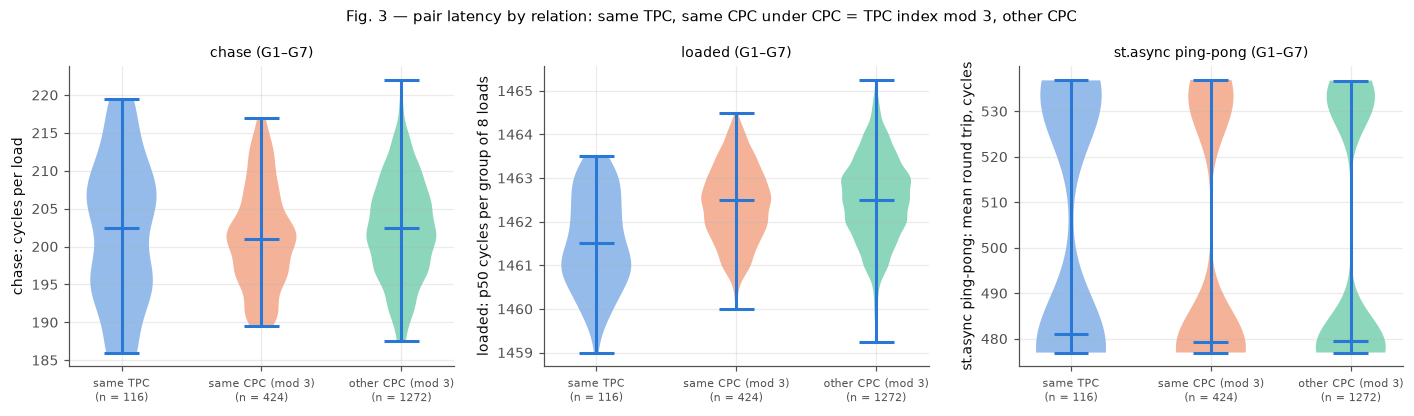

In [9]:
lo_tab = pair_table(LO[LO.schedule.isin(IDLE) & (LO.load_condition == "idle") & (LO.smid_src != LO.smid_dst)], "p50")
VI = VT[VT.schedule.isin(IDLE) & (VT.load_condition == "idle") & (VT.smid_src != VT.smid_dst)]
vis_tab = VI[VI.method == "st_async_mbarrier_nogt"].groupby(["smid_src", "smid_dst"]).rt_mean_cycles.median().rename("median").reset_index()
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
rels = ["same TPC", "same CPC (mod 3)", "other CPC (mod 3)"]
for ax, (tab, lab) in zip(axs, [(ch_tab, "chase: cycles per load"), (lo_tab, "loaded: p50 cycles per group of 8 loads"),
                                 (vis_tab, "st.async ping-pong: mean round trip, cycles")]):
    q = tab[tab.smid_src.map(M.capable) & tab.smid_dst.map(M.capable) & (tab.smid_src.map(GPC) > 0)].copy()
    q["tpc_src"], q["tpc_dst"] = q.smid_src.map(TPCI), q.smid_dst.map(TPCI)
    q["rel"] = relation3(q)
    data = [q.loc[q.rel == r, "median"].values for r in rels]
    vp = ax.violinplot(data, showmedians=True, showextrema=True)
    for k, body in enumerate(vp["bodies"]):
        body.set_facecolor(C[k]); body.set_alpha(0.5)
    ax.set_xticks([1, 2, 3]); ax.set_xticklabels([f"{r}\n(n = {len(x)})" for r, x in zip(rels, data)], fontsize=7.5)
    ax.set_ylabel(lab); ax.set_title(lab.split(":")[0] + " (G1–G7)", fontsize=9)
plt.suptitle("Fig. 3 — pair latency by relation: same TPC, same CPC under CPC = TPC index mod 3, other CPC", fontsize=9.5)
plt.tight_layout(); plt.show()

**Reading 4.3 and Fig. 3.**
- **TPC mates.** TPC mates are not faster in the chase. On the residuals of the additive fit the step is below 0.001 cycles in every GPC.
- **CPC = TPC index mod 3.** The grouping does not stand out, on the raw latencies or on the residuals:
  - In G1–G5 its F rank among all 280 groupings is 0.13–0.75, i.e. dozens of other groupings separate the pairs equally well or better. The best groupings differ from GPC to GPC, and their "step" is negative or positive depending on the GPC.
  - In G6 and G7 (9 TPCs, groups of 3, 3, 3) every grouping gives the same mean for in-group and cross-group pairs (F ≈ 0). An exactly additive matrix has this property when all groups have the same size, so these two GPCs cannot even in principle show a CPC step that is not a pair term.
  - On the residuals every step is < 0.001 cycles.

  The rule fixed before the run (a step above 3 × the per-pair MAD, with the same grouping in all GPCs of a size) is not met, so no CPC grouping is reported: `10__heatmap__cpc_map.csv` carries `none` for every SM.
- **Raw distributions (Fig. 3, left).** The three relations overlap completely. Their medians differ only through the per-SM delays of the TPCs that happen to fall into each class.
- **Loaded latency.** Every pair sits at 1458–1466 cycles per group of 8 loads. The same-TPC class is about 1 cycle faster (F 4–28), which is significant over 240–306 pairs but 0.07 % of the value. The mod-3 classes again show nothing systematic.
- **Visibility round trips.** These show no relation effect either (see 4.5).

### 4.4 GPC sizes, the 12-SM GPC and the SMs that pair only with their mate

In [10]:
gt = pt.groupby("gpc").p.agg(["mean", "min", "max"]).rename(columns=lambda c: f"p {c}")
gt.insert(0, "SMs (cluster-capable)", M[M.capable].groupby("gpc").size())
gt["pair median"] = ch_tab.assign(g=ch_tab.smid_src.map(GPC)).groupby("g")["median"].median()
display(gt.style.format(precision=2).set_caption("Per GPC: delay p(i) and pair latency (cycles)"))
mates = ch_tab[(ch_tab.smid_src // 2 == ch_tab.smid_dst // 2)].copy()
mates["capable"] = mates.smid_src.map(M.capable)
mates["gpc"] = mates.smid_src.map(GPC)
mo = mates[~mates.capable][["smid_src", "smid_dst", "gpc", "median", "mad", "n"]]
display(mo.set_index(["smid_src", "smid_dst"]).style.format(precision=3).set_caption("TPCs 62–65 (only CS 2): the two directions"))
display(Markdown(f"TPC-mate pairs of all other TPCs: median {mates[mates.capable]['median'].median():.2f}, range "
                 f"{mates[mates.capable]['median'].min():.2f}–{mates[mates.capable]['median'].max():.2f} cycles."))

,SMs (cluster-capable),p mean,p min,p max,pair median
gpc,,,,,
0,8,105.13,99.50,110.50,210.00
1,16,99.97,93.00,108.00,200.51
2,16,99.97,93.00,108.00,200.51
3,16,101.35,93.00,110.50,202.51
4,16,102.47,93.00,111.50,205.01
5,16,101.35,93.00,110.50,202.51
6,18,100.97,93.00,110.50,202.00
7,18,100.97,93.00,110.50,202.00


,,gpc,median,mad,n
smid_src,smid_dst,,,,
124,125,0,192.504,0.000,20
125,124,0,192.504,0.000,20
126,127,4,198.505,0.000,20
127,126,4,198.504,0.000,20
128,129,5,196.005,0.000,20
129,128,5,196.004,0.000,20
130,131,0,196.005,0.000,20
131,130,0,196.005,0.000,20


TPC-mate pairs of all other TPCs: median 202.51, range 186.00–219.51 cycles.

**Reading 4.4.**
- The 18-SM GPCs are not slower than the 16-SM ones; the per-SM delays cover the same range. The extra TPC of G6/G7 (index 8) sits in the middle of that range.
- The 12-SM GPC G0 has the longest delays (p 99.5–110.5; its cluster-capable pairs cost 203–218.5 cycles, median 210).
- The four TPCs that only ever form 2-CTA clusters (SMs 124–131) reach their mate in 192–199 cycles, inside the range of the other TPC-mate pairs. Their network position is therefore an ordinary one.

### 4.5 Store visibility for every pair

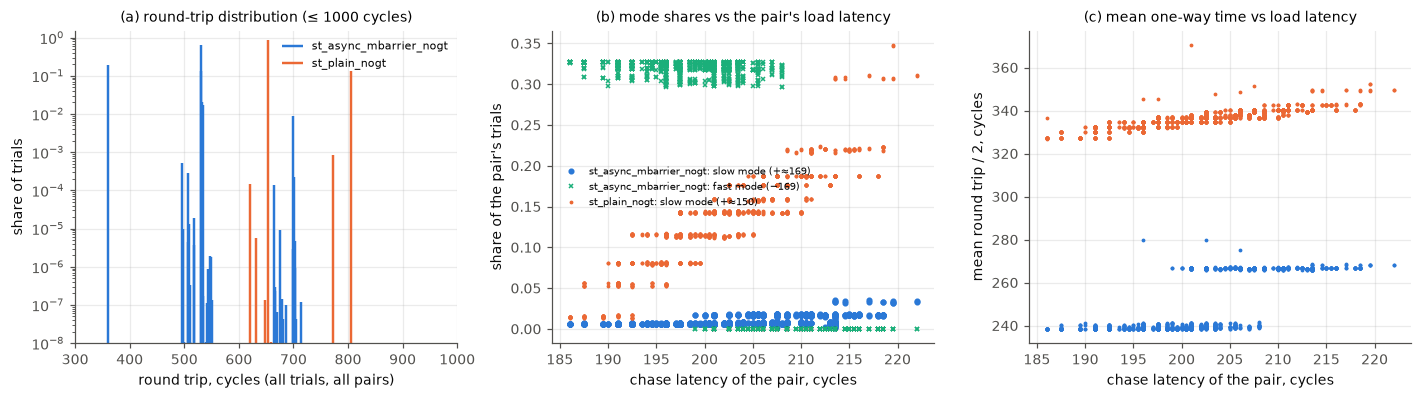

,main_mode,slow_median,slow_min,slow_max,fast_max,mean_rt_min,mean_rt_max,"corr(slow share, chase)"
method,,,,,,,,
st_async_mbarrier,536,0.118,0.006,0.233,0.000,536.961,635.184,0.708
st_async_mbarrier_nogt,531,0.007,0.001,0.036,0.327,476.931,559.836,0.588
st_plain,662,0.323,0.177,0.453,0.000,689.053,773.515,0.891
st_plain_nogt,652,0.142,0.013,0.348,0.000,653.944,740.931,0.887


Trials above 1000 cycles (rare stalls of up to 3,540,695, 3,369,598 cycles): st_async_mbarrier_nogt: 4 of 91,040,000, st_plain_nogt: 11 of 91,040,000.

,share of pairs with the fast mode,pairs
L,,
≤ 198,1.00,578
199–208,0.57,896
≥ 209,0.00,402


In [11]:
VH = read_runs("10__heatmap__visibility_hist.csv", IDS)
vh = VH[VH.schedule.isin(IDLE) & (VH.load_condition == "idle") & (VH.quantity == "rt_cycles")]
res = []
for meth, g in vh.groupby("method"):
    tot = g.groupby("value")["count"].sum()
    main = tot.idxmax()
    gg = g.assign(slow=g.value > main + 75, fast=g.value < main - 75)
    f = gg.groupby(["smid_src", "smid_dst"]).apply(lambda x: pd.Series({"n": x["count"].sum(),
                                                                         "slow": x.loc[x.slow, "count"].sum() / x["count"].sum(),
                                                                         "fast": x.loc[x.fast, "count"].sum() / x["count"].sum(),
                                                                         "mean": (x.value * x["count"]).sum() / x["count"].sum()}))
    f["method"], f["main"] = meth, main
    res.append(f.reset_index())
VF = pd.concat(res).merge(ch_tab[["smid_src", "smid_dst", "median"]].rename(columns={"median": "chase"}), on=["smid_src", "smid_dst"])
fig, axs = plt.subplots(1, 3, figsize=(13, 3.7))
far = {}
for k, meth in enumerate(["st_async_mbarrier_nogt", "st_plain_nogt"]):
    tot = vh[vh.method == meth].groupby("value")["count"].sum()
    far[meth] = (int(tot[tot.index > 1000].sum()), int(tot.sum()), int(tot.index.max()))
    tot = tot[tot.index <= 1000]
    axs[0].vlines(tot.index + (k - 0.5) * 2, 1e-9, tot.values / far[meth][1], color=C[k], lw=1.6, label=meth)
    v = VF[VF.method == meth]
    axs[1].plot(v.chase, v.slow, "." if k else "o", ms=3, color=C[k], label=f"{meth}: slow mode (+≈{150 if k else 169})")
    if k == 0:
        axs[1].plot(v.chase, v.fast, "x", ms=3, color=C[2], label=f"{meth}: fast mode (−169)")
    axs[2].plot(v.chase, v["mean"] / 2, ".", ms=3, color=C[k], label=meth)
axs[0].set_yscale("log"); axs[0].set_ylim(1e-8, 1.5); axs[0].set_xlim(300, 1000); axs[0].set_xlabel("round trip, cycles (all trials, all pairs)"); axs[0].set_ylabel("share of trials")
axs[0].legend(fontsize=7); axs[0].set_title("(a) round-trip distribution (≤ 1000 cycles)", fontsize=9)
axs[1].set_xlabel("chase latency of the pair, cycles"); axs[1].set_ylabel("share of the pair's trials"); axs[1].legend(fontsize=6.5)
axs[1].set_title("(b) mode shares vs the pair's load latency", fontsize=9)
axs[2].set_xlabel("chase latency of the pair, cycles"); axs[2].set_ylabel("mean round trip / 2, cycles")
axs[2].set_title("(c) mean one-way time vs load latency", fontsize=9)
plt.tight_layout(); plt.show()
t = VF.groupby("method").agg(main_mode=("main", "first"), slow_median=("slow", "median"), slow_min=("slow", "min"), slow_max=("slow", "max"),
                             fast_max=("fast", "max"), mean_rt_min=("mean", "min"), mean_rt_max=("mean", "max"))
t["corr(slow share, chase)"] = VF.groupby("method").apply(lambda x: x.slow.corr(x.chase))
display(t.style.format(precision=3).set_caption("Ping-pong round trips per pair (idle; 1000 trials × ≥ 20 launches per pair)"))
display(Markdown("Trials above 1000 cycles (rare stalls of up to " + ", ".join(f"{v[2]:,}" for v in far.values()) + " cycles): " +
                 ", ".join(f"{k}: {v[0]} of {v[1]:,}" for k, v in far.items()) + "."))
va = VF[VF.method == "st_async_mbarrier_nogt"].assign(L=lambda x: x.chase.round())
fz = va.assign(has_fast=va.fast > 0.05).groupby(pd.cut(va.L, [180, 198.5, 208.5, 230], labels=["≤ 198", "199–208", "≥ 209"])).has_fast.agg(["mean", "size"])
display(fz.rename(columns={"mean": "share of pairs with the fast mode", "size": "pairs"}).style.format(precision=2)
        .set_caption("st.async + mbarrier: pairs whose trials include the −169-cycle mode, by chase latency (the property is symmetric in direction)"))
ow = VT[VT.method.isin(["st_async_mbarrier", "st_plain"]) & (VT.load_condition == "idle") & VT.schedule.isin(IDLE)]
display(ow.groupby("method")[["ow_mean_ns", "ob_mean_ns"]].describe(percentiles=[0.5]).style.format(precision=1)
        .set_caption("One-way times from %globaltimer (variants with timer reads), means of 32-ns ticks per pair and launch: q→p (ow) and p→q (ob)"))

**Reading 4.5.**
- **Quantised round trips.** The round trip of a hand-off takes one of a few fixed values:
  - `st.async` + mbarrier: 531 cycles, one step of ≈ 169 cycles less (362), or one step more (≈ 700);
  - plain store + polling: 652 cycles, or ≈ 150 more.

  The main value is the **same for every pair**: the 186–222-cycle spread of the load latency does not appear in it.
- **Distance decides which steps a pair can reach.** Two things depend on the pair, and both are fixed per SM pair: they are the same in every launch and at every rank position (the same SM pair sits at different ranks in different target sets), and the same in both directions.
  - **Fast mode (`st.async`).** Pairs whose load latency is ≤ 198 cycles complete about a third of their hand-offs one step early (362 cycles), pairs at ≥ 209 cycles never do, and pairs in between split.
  - **Slow mode (plain store).** The share of trials one step late rises from ≈ 1 % for the closest pairs to ≈ 35 % for the farthest.

  The *mean* hand-off time therefore grows with distance (c) while the typical one does not. A hand-off behaves as if it had to catch a periodic slot of ≈ 150–170 cycles (≈ 100 ns): a shorter path sometimes catches an earlier slot, a longer path misses its slot more often.
- **One-way times** from the global timer (≈ 150–175 ns with `st.async`, ≈ 215 ns plain) carry the 32-ns tick of that timer. They are consistent with half the round trip.

### 4.6 Background load (Fig. 4)

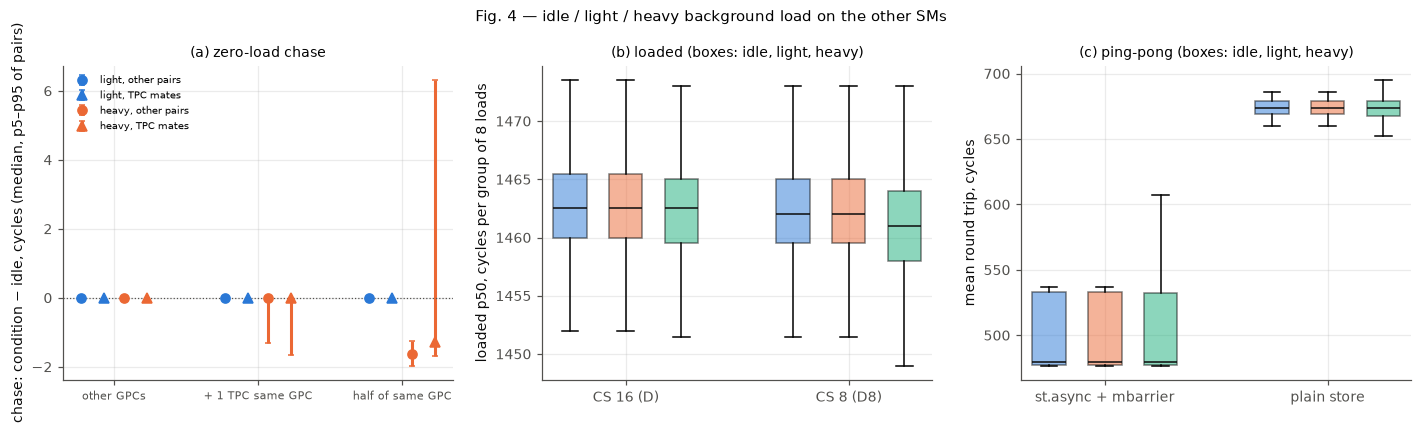

In [12]:
def deltas(sch):
    d = REM[REM.schedule == sch]
    pm = d.groupby(["gpc", "subset", "load_condition", "smid_src", "smid_dst"]).cycles_per_hop.median().unstack("load_condition").reset_index()
    pm["same_tpc"] = pm.smid_src // 2 == pm.smid_dst // 2
    return pm


D16, D8 = deltas("D"), deltas("D8")
D16["where"] = np.where(D16.gpc.isin([1, 2, 3]), "CS 16, G1–G3: background only in other GPCs",
                        "CS 16, G4–G7: + one TPC of the same GPC")
D8["where"] = "CS 8: other half of the same GPC busy"
DD = pd.concat([D16, D8])
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
groups = ["CS 16, G1–G3: background only in other GPCs", "CS 16, G4–G7: + one TPC of the same GPC", "CS 8: other half of the same GPC busy"]
for k, cond in enumerate(["light", "heavy"]):
    for j, w in enumerate(groups):
        for st, mk in [(False, "o"), (True, "^")]:
            x = (DD[(DD["where"] == w) & (DD.same_tpc == st)][cond] - DD[(DD["where"] == w) & (DD.same_tpc == st)]["idle"]).dropna()
            axs[0].errorbar(j + (k - 0.5) * 0.3 + (0.08 if st else -0.08), x.median(), yerr=[[x.median() - x.quantile(0.05)], [x.quantile(0.95) - x.median()]],
                            fmt=mk, color=C[k], capsize=2, label=f"{cond}, {'TPC mates' if st else 'other pairs'}" if j == 0 else None)
axs[0].axhline(0, color=INK2, lw=0.8, ls=":")
axs[0].set_xticks(range(3)); axs[0].set_xticklabels(["other GPCs", "+ 1 TPC same GPC", "half of same GPC"], fontsize=7.5)
axs[0].set_ylabel("chase: condition − idle, cycles (median, p5–p95 of pairs)"); axs[0].legend(fontsize=6.5)
axs[0].set_title("(a) zero-load chase", fontsize=9)
L2 = LO[LO.schedule.isin(["D", "D8"]) & (LO.smid_src != LO.smid_dst)]
for k, cond in enumerate(["idle", "light", "heavy"]):
    for j, sch in enumerate(["D", "D8"]):
        x = L2[(L2.schedule == sch) & (L2.load_condition == cond)].p50
        axs[1].boxplot([x], positions=[j * 4 + k], widths=0.6, showfliers=False, patch_artist=True,
                       boxprops=dict(facecolor=C[k], alpha=0.5), medianprops=dict(color=INK))
axs[1].set_xticks([1, 5]); axs[1].set_xticklabels(["CS 16 (D)", "CS 8 (D8)"]); axs[1].set_ylabel("loaded p50, cycles per group of 8 loads")
axs[1].set_title("(b) loaded (boxes: idle, light, heavy)", fontsize=9)
V2 = VT[VT.schedule.isin(["D", "D8"]) & VT.method.isin(["st_async_mbarrier_nogt", "st_plain_nogt"])]
for k, cond in enumerate(["idle", "light", "heavy"]):
    for j, meth in enumerate(["st_async_mbarrier_nogt", "st_plain_nogt"]):
        x = V2[(V2.method == meth) & (V2.load_condition == cond)].rt_mean_cycles
        axs[2].boxplot([x], positions=[j * 4 + k], widths=0.6, showfliers=False, patch_artist=True,
                       boxprops=dict(facecolor=C[k], alpha=0.5), medianprops=dict(color=INK))
axs[2].set_xticks([1, 5]); axs[2].set_xticklabels(["st.async + mbarrier", "plain store"]); axs[2].set_ylabel("mean round trip, cycles")
axs[2].set_title("(c) ping-pong (boxes: idle, light, heavy)", fontsize=9)
plt.suptitle("Fig. 4 — idle / light / heavy background load on the other SMs", fontsize=9.5)
plt.tight_layout(); plt.show()
t = DD.assign(light_d=DD.light - DD.idle, heavy_d=DD.heavy - DD.idle).groupby(["where", "same_tpc"])[["light_d", "heavy_d"]].describe(percentiles=[0.05, 0.5, 0.95])
display(t.loc[:, pd.IndexSlice[:, ["count", "5%", "50%", "95%", "max"]]].style.format(precision=3)
        .set_caption("Chase, per pair: median over launches of the condition minus the idle median, cycles"))

**Reading Fig. 4.**
- **Light load** (all other SMs busy with their own shared memory) changes nothing: every pair is within 0.001 cycles of idle.
- **Heavy SM-to-SM traffic in other GPCs** changes nothing either (G1–G3 at CS 16): the networks of different GPCs are independent.
- **Heavy traffic inside the same GPC** has a small and unexpected effect:
  - A single busy TPC in the GPC (G4–G7) leaves the median pair unchanged, but makes a minority of pairs **up to 1.3–1.7 cycles faster** (p5).
  - With the other half of the GPC streaming (CS 8), the typical pair is 1.6 cycles faster (other pairs −2.0…−0.9, TPC mates −1.7 at p5).
  - TPC-mate pairs of the measuring cluster instead become slower in some launches, by up to a few percent. Of the 56 measurements that deviate by more than 2 % from the pair's idle value under heavy load, 55 are TPC-mate pairs.

  The shared central point of the GPC therefore sees the other traffic, but at this injection rate it does not queue the measured requests. A busy network even shortens the path by a cycle or two, as if an idle network paid a small wake-up or arbitration cost per request.
- **Loaded latency and ping-pong** are unchanged by any background (b, c).

### 4.7 Cluster size, steering control, fine pass and rare slow measurements

In [13]:
cs_t = IDL.groupby(["cs", "smid_src", "smid_dst"]).cycles_per_hop.median().unstack("cs")
e = REM[REM.schedule == "E"].groupby(["cs", "smid_src", "smid_dst"]).cycles_per_hop.median().rename("none")
i = IDL[IDL.schedule.isin(["A", "B"])].groupby(["cs", "smid_src", "smid_dst"]).cycles_per_hop.median().rename("idle")
j = pd.concat([e, i], axis=1).dropna()
display(pd.DataFrame({"pairs": [cs_t[[8, 16]].dropna().shape[0], len(j)],
                      "median difference": [(cs_t[8] - cs_t[16]).median(), (j.none - j.idle).median()],
                      "max |difference|": [(cs_t[8] - cs_t[16]).abs().max(), (j.none - j.idle).abs().max()]},
                     index=["CS 8 − CS 16 (same pair)", "no placeholders − idle placeholders (lone cluster, same pair)"]).style.format(precision=4))
IDL2 = IDL.join(ch_tab.set_index(["smid_src", "smid_dst"])["median"].rename("pm"), on=["smid_src", "smid_dst"])
r = IDL2.cycles_per_hop / IDL2.pm
allr = REM[REM.load_condition.isin(["idle", "light", "none"])].join(ch_tab.set_index(["smid_src", "smid_dst"])["median"].rename("pm"), on=["smid_src", "smid_dst"])
ra = allr.cycles_per_hop / allr.pm
display(Markdown(f"Pair measurements more than 2 % above the pair's median (idle, light, none): **{int((ra > 1.02).sum())} of {len(ra)}** "
                 f"({100 * (ra > 1.02).mean():.3f} %), ratios {ra[ra > 1.02].min():.2f}–{ra[ra > 1.02].max():.2f}, each in a different launch."))

,pairs,median difference,max |difference|
CS 8 − CS 16 (same pair),1812,-0.0005,0.0009
"no placeholders − idle placeholders (lone cluster, same pair)",296,0.0000,0.0007


Pair measurements more than 2 % above the pair's median (idle, light, none): **18 of 169312** (0.011 %), ratios 1.94–5.22, each in a different launch.

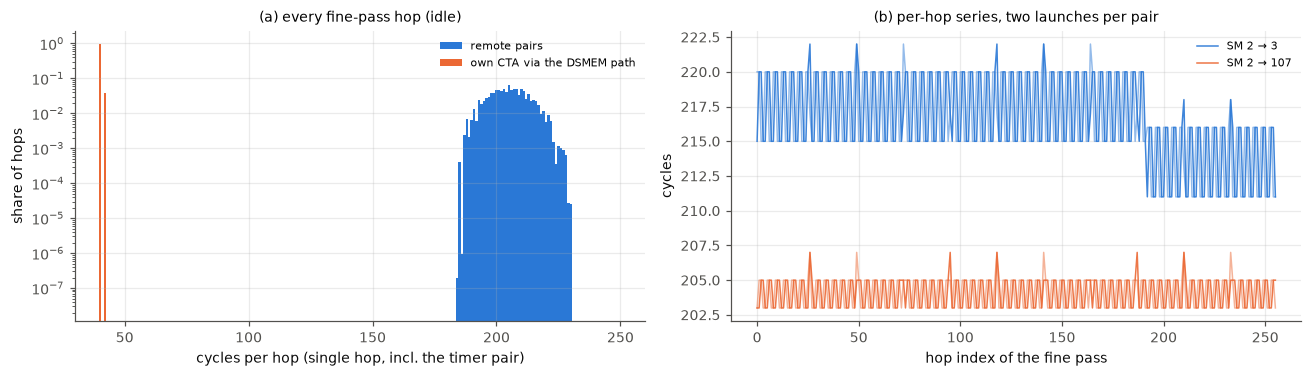

In [14]:
FH = read_runs("10__heatmap__fine_hist.csv", IDS)
fh = FH[FH.schedule.isin(IDLE) & (FH.load_condition == "idle")]
remote = fh[fh.smid_src != fh.smid_dst].groupby("cycles")["count"].sum()
selfh = fh[fh.smid_src == fh.smid_dst].groupby("cycles")["count"].sum()
FR = read_runs("10__heatmap__fine_raw.csv", [RUNS["A"]])
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.5))
a.bar(remote.index, remote / remote.sum(), width=1, color=C[0], label="remote pairs")
a.bar(selfh.index, selfh / selfh.sum(), width=1, color=C[1], label="own CTA via the DSMEM path")
a.set_yscale("log"); a.set_xlim(30, 260); a.set_xlabel("cycles per hop (single hop, incl. the timer pair)"); a.set_ylabel("share of hops")
a.legend(fontsize=7); a.set_title("(a) every fine-pass hop (idle)", fontsize=9)
for k, (s, dd) in enumerate([(2, 3), (2, 107), (12, 121)]):
    x = FR[(FR.smid_src == s) & (FR.smid_dst == dd)]
    if len(x):
        for li, (_, y) in enumerate(x.groupby("launch_idx")):
            b.plot(y.hop_idx, y.cycles, lw=1, color=C[k], alpha=0.9 if li == 0 else 0.5, label=f"SM {s} → {dd}" if li == 0 else None)
b.set_xlabel("hop index of the fine pass"); b.set_ylabel("cycles"); b.legend(fontsize=7)
b.set_title("(b) per-hop series, two launches per pair", fontsize=9)
plt.tight_layout(); plt.show()

**Reading 4.7.**
- **Cluster size and placement method.** A pair has the same latency in a 16-CTA and in an 8-CTA cluster, to within 0.001 cycles. With idle placeholders, the lone clusters that the hardware places by itself (in G1 and G0) give exactly the values measured with the steered placement. The placeholders and the steering do not perturb the measurement.
- **Single hops.** Single hops (a) spread over a few cycles around the pair's value plus the timer pair. Per pair, the per-hop series repeats from launch to launch (b): a fixed pattern of a few cycles that depends on the address read, not random jitter. The 4096-hop averages run over the whole 1024-element chain several times and do not depend on it.
- **Rare slow measurements.** A handful of 4096-hop measurements (about one in 10 000) took 2–5 times their pair's value, one pair in one launch each time. This is a rare chip-wide stall of roughly a millisecond, not a property of any pair. The medians are not affected.

In [15]:
n = ncu.copy()
show = ["cs", "chase", "expected_dshared_ld", "sm__sass_inst_executed_op_dshared_ld.sum", "l1tex__t_requests_pipe_lsu_mem_dshared_op_ld.sum",
        "l1tex__m_l1tex2xbar_write_bytes_mem_dshared_op_ld.sum", "l1tex__m_xbar2l1tex_read_bytes_mem_dshared_op_ld.sum",
        "l1tex__m_l1tex2xbar_req_cycles_active_mem_dshared_loopback.sum"]
display(n[[c for c in show if c in n.columns]].set_index(["cs", "chase"]).T.style.format(precision=0)
        .set_caption("Nsight Compute, one lone cluster per profiled launch (chase vs all-exit baseline): DSMEM counters"))

**Counter check.** Nsight Compute counts exactly one DSMEM load instruction and request per remote hop (CS·(CS−1) pairs × 4416 hops), 32 B out and 32 B in per 4-B load. The loopback counter stays at 0: hops into the CTA's own memory never leave the SM and are not network traffic.

## 5. Insights

- **The SM-to-SM network of a GPC is flat to the cycle: a hub with per-SM port delays.** For all 1876 SM pairs that can share a cluster, the dependent remote-load latency is a fixed integer number of cycles: 186–222, median 202. It equals p(source) + p(destination) with a residual below 0.0005 cycles. One delay per SM (93–111.5 cycles, 16 distinct values) explains everything; the delay is the same in the sending and the owning role, and the latency is symmetric in direction.
- **No sub-GPC hierarchy is visible in latency.** There is no TPC shortcut. There is no CPC level: TPC index mod 3 is not a distinguished grouping, and no grouping into threes leaves a residual step (< 0.001 cycles). There is no distance in rank or SM id. The only structure is the port delay, which depends on the TPC's position in the GPC and repeats across GPCs, consistent with a few physical port positions of one central switch.
- **For a 3D-stacked design.** The cost of an SM-to-SM access decomposes into two per-SM terms. Moving an SM closer to the GPC hub shortens every one of its accesses by the same amount. Today the spread is ≈ ±9 cycles per SM (≈ ±5 % of an access); between the best and the worst pair of a GPC it is ≈ 36 cycles. The rest of the ≈ 200 cycles is fixed path and service time, not distance.
- **Hand-off latency is set by a slot, not by distance.** Store → flag round trips take 531 cycles (`st.async` + mbarrier) or 652 cycles (plain store + polling) for every pair, or one quantum of ≈ 150–170 cycles less or more. The pair's distance only changes how often a quantum is gained or lost: near pairs (≤ 198 cycles) gain one in about a third of `st.async` hand-offs, far pairs lose one in up to 35 % of plain hand-offs. Distance costs a probability rather than cycles.
- **Isolation.** Background traffic in other GPCs, and local shared-memory traffic anywhere, has no effect on DSMEM latency. Heavy SM-to-SM traffic inside the same GPC shifts the zero-load latency by only −2 to +8 cycles (most pairs −2 to 0). The loaded latency (≈ 1462 cycles per group of 8 loads, limited by the source's injection rate) is the same for every pair and under every background.
- **Limitations.**
  - Latencies are SM cycles of the issuing SM. The GPCs run at slightly different clocks under the lock (up to 0.8 %), which could shift whole GPCs by ≈ 1 cycle in ns terms but not within a GPC.
  - The test detects pair terms in *latency*. A hierarchy that only shows under bandwidth saturation is not excluded.
  - The SMs 124–131 can only be measured with their mate.